# TP3 - Optimización de Modelos de Machine Learning

**Grupo:** 2

En este trabajo práctico se aborda un problema de **clasificación supervisada**: predecir si una reserva de infraestructura GPU será cancelada antes de su ejecución.



In [1]:
# IMPORTS

import pandas as pd
# pandas sirve para trabajar con datos en forma de tablas (DataFrames).

import numpy as np
import matplotlib.pyplot as plt

# Para que pandas muestre todas las columnas al imprimir un DataFrame
pd.set_option("display.max_columns", None)

## 1. Descripción del dataset

### 1.1 Contexto

El dataset contiene información sobre **reservas de GPUs** en una plataforma de cómputo.

Una **GPU** es un procesador especializado en realizar muchos cálculos en paralelo, muy utilizado para entrenar modelos de machine learning. Como son costosas, muchos usuarios no las compran sino que las **alquilan por horas** a plataformas que disponen de muchas GPUs conectadas entre sí (un *entorno de cómputo distribuido*).

Cada fila del dataset representa **una reserva**: un cliente solicita cierta cantidad y tipo de GPUs, para una fecha determinada y durante una cantidad de horas. Antes de esa fecha, el cliente puede **cancelar la reserva**. Predecir qué reservas se van a cancelar le permite a la plataforma reasignar esos recursos a otros clientes y evitar que queden sin uso.

La información disponible puede agruparse en:

- **Características temporales:** cuándo se programó la ejecución y con cuánta anticipación se hizo la reserva.
- **Recursos solicitados:** horas GPU, procesos, tipo de GPU y almacenamiento.
- **Historial del cliente:** si ya usó la plataforma y cuántas reservas canceló o completó antes.
- **Características económicas y contractuales:** costo por hora y tipo de compromiso.

La variable objetivo es `canceled_job`, que indica si la reserva fue cancelada (1) o no (0).

Predecir cancelaciones con anticipación permitiría a la plataforma planificar mejor la capacidad de cómputo, por ejemplo reasignando recursos o aplicando sobreventa controlada.

In [2]:
# CARGA DEL DATASET

# El CSV está en la carpeta data/, dentro del repo
df = pd.read_csv("data/gpu_resource_reservations.csv")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 47842
Columnas: 34


,canceled_job,hours_before_execution,execution_year,execution_month,execution_week,execution_day,peak_gpu_hours,offpeak_gpu_hours,num_primary_processes,num_auxiliary_processes,num_background_processes,service_tier,client_region,client_type,request_channel,returning_client,previous_job_cancellations,successful_previous_jobs,reserved_gpu_type,assigned_gpu_type,resource_modifications,reservation_commitment,orchestration_agent_id,organization_id,queue_wait_time,workload_profile,estimated_cost_per_hour,reserved_storage_units,special_resource_requests,execution_status,execution_status_date,total_processes,total_gpu_hours,high_value_client
0,0,6,2015,7,27,1,0,16,1,0.0,0,priority,PRT,managed_account,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,6.0,NaN,0,single_experiment,0.000,0,0,completed,2015-07-03,1.0,16,0
1,1,88,2015,7,27,1,0,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-07-01,2.0,32,0
2,1,92,2015,7,27,1,16,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,2,canceled,2015-06-23,2.0,48,0
3,1,79,2015,7,27,2,0,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-06-25,2.0,24,0
4,1,62,2015,7,27,2,16,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,8.0,NaN,0,single_experiment,3.825,0,1,no_show,2015-07-02,2.0,40,0


### 1.2 Diccionario de variables

A continuación se construye una tabla con todas las variables del dataset. Para cada una se muestra:

- **descripcion:** qué representa.
- **tipo_pandas:** cómo la interpreta pandas.
- **valores_unicos:** cantidad de valores distintos.
- **nulos:** cantidad de valores faltantes.
- **valores_posibles:** si tiene pocos valores, se listan todos; si es numérica con muchos valores, se muestra su rango; si es categórica con muchas categorías, se muestran las más frecuentes.

In [3]:
# DICCIONARIO DE VARIABLES

# Para que pandas muestre el texto completo de cada celda de la tabla
pd.set_option("display.max_colwidth", None)

# Descripción de cada variable (tomada de la consigna del TP)
descripciones = {
    "canceled_job": "Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.",
    "hours_before_execution": "Horas entre la creación de la reserva y el inicio programado de ejecución.",
    "execution_year": "Año del inicio programado de ejecución.",
    "execution_month": "Mes del inicio programado de ejecución.",
    "execution_week": "Semana del año del inicio programado de ejecución.",
    "execution_day": "Día del mes del inicio programado de ejecución.",
    "peak_gpu_hours": "Horas GPU reservadas en períodos de alta demanda.",
    "offpeak_gpu_hours": "Horas GPU reservadas en períodos de baja demanda.",
    "num_primary_processes": "Número de procesos principales asociados al workload.",
    "num_auxiliary_processes": "Número de procesos auxiliares asociados al workload.",
    "num_background_processes": "Número de procesos secundarios o de mantenimiento asociados al workload.",
    "service_tier": "Nivel de servicio contratado para la reserva.",
    "client_region": "País o región de procedencia del cliente.",
    "client_type": "Tipo de cliente que realiza la solicitud.",
    "request_channel": "Canal utilizado para realizar la reserva.",
    "returning_client": "Indica si el cliente ya había utilizado previamente la plataforma.",
    "previous_job_cancellations": "Cantidad de reservas canceladas previamente por el cliente.",
    "successful_previous_jobs": "Cantidad de reservas completadas exitosamente por el cliente.",
    "reserved_gpu_type": "Tipo de GPU solicitado originalmente.",
    "assigned_gpu_type": "Tipo de GPU finalmente asignado para la ejecución.",
    "resource_modifications": "Número de modificaciones realizadas sobre la reserva original.",
    "reservation_commitment": "Tipo de compromiso contractual asociado a la reserva.",
    "orchestration_agent_id": "Identificador del agente de orquestación asociado a la reserva.",
    "organization_id": "Identificador de la organización asociada a la reserva.",
    "queue_wait_time": "Tiempo de espera en cola antes de la asignación definitiva de recursos.",
    "workload_profile": "Perfil general o tipo de workload solicitado.",
    "estimated_cost_per_hour": "Costo estimado en USD por hora para el conjunto de recursos de la reserva.",
    "reserved_storage_units": "Cantidad de unidades de almacenamiento reservadas.",
    "special_resource_requests": "Número de solicitudes especiales asociadas a la reserva.",
    # Columnas que NO figuran en la consigna (descripción propia)
    "execution_status": "(No figura en la consigna) Estado final de la reserva.",
    "execution_status_date": "(No figura en la consigna) Fecha del último cambio de estado de la reserva.",
    "total_processes": "(No figura en la consigna) Total de procesos de la reserva.",
    "total_gpu_hours": "(No figura en la consigna) Total de horas GPU reservadas.",
    "high_value_client": "(No figura en la consigna) Indicador binario de cliente de alto valor.",
}


def valores_posibles(serie, max_categorias=12):
    """
    Devuelve un texto con los valores que toma una variable:
    - Si tiene pocos valores distintos, los lista todos.
    - Si es numérica con muchos valores, muestra el rango y la mediana.
    - Si es categórica con muchas categorías, muestra las 5 más frecuentes.
    """
    serie = serie.dropna()
    n_unicos = serie.nunique()

    # Numérica con muchos valores -> rango
    if pd.api.types.is_numeric_dtype(serie) and n_unicos > max_categorias:
        return f"Rango: {serie.min():g} a {serie.max():g} (mediana {serie.median():g})"

    # Pocos valores -> los listamos todos
    if n_unicos <= max_categorias:
        valores = sorted(serie.unique())
        return ", ".join(f"{v:g}" if isinstance(v, float) else str(v) for v in valores)

    # Categórica con muchas categorías -> las más frecuentes
    top = serie.value_counts().head(5).index.tolist()
    return f"{n_unicos} categorías. Más frecuentes: {', '.join(map(str, top))}"


diccionario = pd.DataFrame({
    "descripcion": pd.Series(descripciones),
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "valores_posibles": [valores_posibles(df[col]) for col in df.columns],
})

diccionario

,descripcion,tipo_pandas,valores_unicos,nulos,valores_posibles
canceled_job,Variable objetivo. Indica si la reserva fue cancelada o no llegó a ejecutarse.,int64,2,0,"0, 1"
hours_before_execution,Horas entre la creación de la reserva y el inicio programado de ejecución.,int64,436,0,Rango: 0 a 629 (mediana 72)
execution_year,Año del inicio programado de ejecución.,int64,3,0,"2015, 2016, 2017"
execution_month,Mes del inicio programado de ejecución.,int64,12,0,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12"
execution_week,Semana del año del inicio programado de ejecución.,int64,53,0,Rango: 1 a 53 (mediana 27)
execution_day,Día del mes del inicio programado de ejecución.,int64,31,0,Rango: 1 a 31 (mediana 16)
peak_gpu_hours,Horas GPU reservadas en períodos de alta demanda.,int64,14,0,Rango: 0 a 128 (mediana 8)
offpeak_gpu_hours,Horas GPU reservadas en períodos de baja demanda.,int64,27,0,Rango: 0 a 328 (mediana 16)
num_primary_processes,Número de procesos principales asociados al workload.,int64,5,0,"0, 1, 2, 3, 4"
num_auxiliary_processes,Número de procesos auxiliares asociados al workload.,float64,4,1,"0, 1, 2, 3"


### 1.3 Descripción de las variables

A partir del diccionario anterior, se describen las variables agrupadas según el tipo de información que aportan.

#### Variable objetivo

- **`canceled_job`**: indica si la reserva fue cancelada o no llegó a ejecutarse. Toma los valores **0** (no cancelada) y **1** (cancelada).

#### Variables temporales

- **`hours_before_execution`**: horas entre la creación de la reserva y el inicio programado de ejecución. Va de **0 a 629**, con mediana 72.
- **`execution_year`**: año del inicio programado. Toma los valores **2015, 2016 y 2017**.
- **`execution_month`**: mes del inicio programado. Va de **1 a 12**.
- **`execution_week`**: semana del año del inicio programado. Va de **1 a 53**.
- **`execution_day`**: día del mes del inicio programado. Va de **1 a 31**.

#### Recursos solicitados

- **`peak_gpu_hours`**: horas GPU reservadas en períodos de alta demanda. Va de **0 a 128**, con mediana 8.
- **`offpeak_gpu_hours`**: horas GPU reservadas en períodos de baja demanda. Va de **0 a 328**, con mediana 16.
- **`num_primary_processes`**: número de procesos principales. Toma valores de **0 a 4**.
- **`num_auxiliary_processes`**: número de procesos auxiliares. Toma valores de **0 a 3** y tiene **1 valor faltante**.
- **`num_background_processes`**: número de procesos secundarios o de mantenimiento. Toma los valores **0, 1, 2, 9 y 10**.
- **`reserved_gpu_type`**: tipo de GPU solicitado originalmente. Tiene **8 categorías**: GPU_T1, GPU_T2, GPU_T3, GPU_T4, GPU_T5, GPU_T6, GPU_T7 y GPU_T12.
- **`assigned_gpu_type`**: tipo de GPU finalmente asignado. Tiene **9 categorías**: las mismas que la anterior más GPU_T10.
- **`reserved_storage_units`**: unidades de almacenamiento reservadas. Toma los valores **0, 1 y 2**.
- **`special_resource_requests`**: número de solicitudes especiales. Toma valores de **0 a 5**.
- **`queue_wait_time`**: tiempo de espera en cola antes de la asignación de recursos. Va de **0 a 391**, con mediana 0.
- **`resource_modifications`**: número de modificaciones sobre la reserva original. Va de **0 a 20**, con mediana 0.
- **`workload_profile`**: tipo de workload solicitado. Tiene **4 categorías**: single_experiment, multi_run_experiment, long_term_contract y team_project.

#### Información del cliente

- **`client_type`**: tipo de cliente. Tiene **8 categorías**: cloud_marketplace, managed_account, research_consortium, independent_client, enterprise_client, sponsored_project, high_priority_partner y unknown.
- **`client_region`**: país de procedencia del cliente. Tiene **149 categorías**; las más frecuentes son PRT, FRA, DEU, GBR y ESP. Tiene **20 valores faltantes**.
- **`request_channel`**: canal por el que se hizo la reserva. Tiene **5 categorías**: broker_platform, api_direct, enterprise_portal, scheduler_gateway y unknown.
- **`returning_client`**: indica si el cliente ya había usado la plataforma. Toma los valores **0 y 1**.
- **`previous_job_cancellations`**: reservas canceladas previamente por el cliente. Toma valores entre **0 y 21**.
- **`successful_previous_jobs`**: reservas completadas exitosamente por el cliente. Va de **0 a 72**, con mediana 0.

#### Variables económicas y contractuales

- **`service_tier`**: nivel de servicio contratado. Tiene **4 categorías**: basic, standard, priority y enterprise.
- **`reservation_commitment`**: tipo de compromiso contractual. Tiene **3 categorías**: no_commitment, locked_allocation y flexible_commitment.
- **`estimated_cost_per_hour`**: costo estimado en USD por hora. Va de **0 a 270**, con mediana 5.

#### Identificadores

- **`orchestration_agent_id`**: identificador del agente de orquestación. Tiene **194 valores distintos** y **5.035 faltantes**.
- **`organization_id`**: identificador de la organización. Tiene **175 valores distintos** y **45.540 faltantes**.

Aunque pandas los interpreta como números, son **etiquetas**: el agente 200 no es "mayor" que el agente 100. Por eso se tratarán como variables categóricas.

#### Variables que no figuran en la consigna

El dataset incluye cinco columnas que no aparecen en la descripción de la consigna:

- **`execution_status`**: estado final de la reserva. Tiene **3 categorías**: completed, canceled y no_show.
- **`execution_status_date`**: fecha del último cambio de estado. Tiene **849 fechas distintas**.
- **`total_processes`**: total de procesos. Toma valores entre **0 y 12**.
- **`total_gpu_hours`**: total de horas GPU. Va de **0 a 456**.
- **`high_value_client`**: indicador de cliente de alto valor. Toma los valores **0 y 1**.

Como no tienen descripción oficial, a continuación verificamos qué representan.

In [4]:
# VERIFICACIÓN DE LAS VARIABLES QUE NO FIGURAN EN LA CONSIGNA

# 1) ¿total_gpu_hours es la suma de las horas peak y offpeak?
suma_horas = df["peak_gpu_hours"] + df["offpeak_gpu_hours"]
print("total_gpu_hours = peak + offpeak en el",
      round((df["total_gpu_hours"] == suma_horas).mean() * 100, 3), "% de las filas")

# 2) ¿total_processes es la suma de los tres tipos de procesos?
suma_procesos = (df["num_primary_processes"]
                 + df["num_auxiliary_processes"]
                 + df["num_background_processes"])
print("total_processes = suma de procesos en el",
      round((df["total_processes"] == suma_procesos).mean() * 100, 3), "% de las filas")

# 3) Las horas GPU, ¿vienen en bloques de 8 horas?
multiplos_8 = (df["peak_gpu_hours"] % 8 == 0) & (df["offpeak_gpu_hours"] % 8 == 0)
print("peak y offpeak son múltiplos de 8 en el",
      round(multiplos_8.mean() * 100, 3), "% de las filas")

# 4) ¿high_value_client se relaciona con el costo por hora?
print("\nCosto por hora según high_value_client:")
print(df.groupby("high_value_client")["estimated_cost_per_hour"].describe().round(2))

# 5) ¿execution_status coincide con el target?
print("\nexecution_status vs canceled_job:")
print(pd.crosstab(df["execution_status"], df["canceled_job"]))

total_gpu_hours = peak + offpeak en el 100.0 % de las filas
total_processes = suma de procesos en el 99.998 % de las filas
peak y offpeak son múltiplos de 8 en el 100.0 % de las filas

Costo por hora según high_value_client:
                     count  mean   std  min   25%   50%   75%     max
high_value_client                                                    
0                  36525.0  4.55  1.24  0.0  3.75  4.55  5.49    6.62
1                  11317.0  7.56  3.24  0.0  6.84  7.50  8.50  270.00

execution_status vs canceled_job:
canceled_job          0      1
execution_status              
canceled              0  19416
completed         27887      0
no_show               0    539


#### Conclusiones sobre las variables que no figuran en la consigna

- **`total_gpu_hours`** es exactamente la suma de `peak_gpu_hours` y `offpeak_gpu_hours` (100% de las filas). Es una variable **redundante**.
- **`total_processes`** es la suma de los tres tipos de procesos (99,998% de las filas; la única excepción es la fila con el valor faltante). También es **redundante**.
- Las horas GPU vienen siempre en **bloques de 8 horas**, porque `peak_gpu_hours` y `offpeak_gpu_hours` son múltiplos de 8 en el 100% de las filas.
- **`high_value_client`**: los clientes marcados con 1 tienen un costo por hora mayor en promedio (7,56 vs. 4,55 USD), pero no hay un umbral exacto que los separe. Se conserva como variable.
- **`execution_status`** coincide exactamente con el target: "canceled" y "no_show" siempre corresponden a `canceled_job = 1`, y "completed" a `canceled_job = 0`. Es **data leakage**: el estado final de la reserva no se conoce al momento de predecir. Lo mismo ocurre con **`execution_status_date`**, que registra la fecha de la cancelación o de la finalización. **Ambas se eliminarán.**

## 2. Exploración inicial

En esta sección se analiza la estructura del dataset: el tipo de cada variable, los valores faltantes, el balance de la variable objetivo y las categorías poco frecuentes.

Todavía **no** se analiza la relación de cada variable con el target. Ese análisis se hará después de separar train y test, para evitar data leakage.

### 2.1 Clasificación de las variables

El tipo que asigna pandas no siempre coincide con el tipo conceptual de la variable. Por ejemplo, `orchestration_agent_id` aparece como número, pero es un **identificador**: el agente 200 no es "mayor" que el agente 100. Por eso clasificamos cada variable manualmente según su significado.

In [5]:
# CLASIFICACIÓN CONCEPTUAL DE CADA VARIABLE

tipos_variables = {
    "canceled_job": "Target (binaria)",
    "hours_before_execution": "Numérica discreta",
    "execution_year": "Temporal",
    "execution_month": "Temporal",
    "execution_week": "Temporal",
    "execution_day": "Temporal",
    "peak_gpu_hours": "Numérica discreta",
    "offpeak_gpu_hours": "Numérica discreta",
    "num_primary_processes": "Numérica discreta",
    "num_auxiliary_processes": "Numérica discreta",
    "num_background_processes": "Numérica discreta",
    "service_tier": "Categórica nominal",
    "client_region": "Categórica nominal (alta cardinalidad)",
    "client_type": "Categórica nominal",
    "request_channel": "Categórica nominal",
    "returning_client": "Binaria",
    "previous_job_cancellations": "Numérica discreta",
    "successful_previous_jobs": "Numérica discreta",
    "reserved_gpu_type": "Categórica nominal",
    "assigned_gpu_type": "Categórica nominal",
    "resource_modifications": "Numérica discreta",
    "reservation_commitment": "Categórica nominal",
    "orchestration_agent_id": "Identificador (categórica, alta cardinalidad)",
    "organization_id": "Identificador (categórica, alta cardinalidad)",
    "queue_wait_time": "Numérica discreta",
    "workload_profile": "Categórica nominal",
    "estimated_cost_per_hour": "Numérica continua",
    "reserved_storage_units": "Numérica discreta",
    "special_resource_requests": "Numérica discreta",
    "execution_status": "Leakage",
    "execution_status_date": "Leakage",
    "total_processes": "Redundante (suma de procesos)",
    "total_gpu_hours": "Redundante (suma de horas GPU)",
    "high_value_client": "Binaria",
}

# Agregamos la clasificación al diccionario armado en la sección 1
diccionario["tipo_variable"] = diccionario.index.map(tipos_variables)

# Cuántas variables hay de cada tipo
print(diccionario["tipo_variable"].value_counts())

# Tabla ordenada por tipo de variable
diccionario.sort_values("tipo_variable")[["tipo_variable", "tipo_pandas", "valores_unicos"]]

tipo_variable
Numérica discreta                                12
Categórica nominal                                7
Temporal                                          4
Binaria                                           2
Identificador (categórica, alta cardinalidad)     2
Leakage                                           2
Target (binaria)                                  1
Categórica nominal (alta cardinalidad)            1
Numérica continua                                 1
Redundante (suma de procesos)                     1
Redundante (suma de horas GPU)                    1
Name: count, dtype: int64


,tipo_variable,tipo_pandas,valores_unicos
high_value_client,Binaria,int64,2
returning_client,Binaria,int64,2
request_channel,Categórica nominal,str,5
client_type,Categórica nominal,str,8
service_tier,Categórica nominal,str,4
reservation_commitment,Categórica nominal,str,3
assigned_gpu_type,Categórica nominal,str,9
reserved_gpu_type,Categórica nominal,str,8
workload_profile,Categórica nominal,str,4
client_region,Categórica nominal (alta cardinalidad),str,149


El dataset tiene principalmente **variables numéricas discretas** (12), que son conteos como cantidad de procesos, horas o modificaciones, y **variables categóricas nominales** (7).

Además hay 4 variables temporales, 2 binarias, 2 identificadores y 1 numérica continua (`estimated_cost_per_hour`). Las 4 variables restantes (2 con leakage y 2 redundantes) se eliminarán más adelante.

### 2.2 Valores faltantes

                         nulos  porcentaje
organization_id          45540       95.19
orchestration_agent_id    5035       10.52
client_region               20        0.04
num_auxiliary_processes      1        0.00


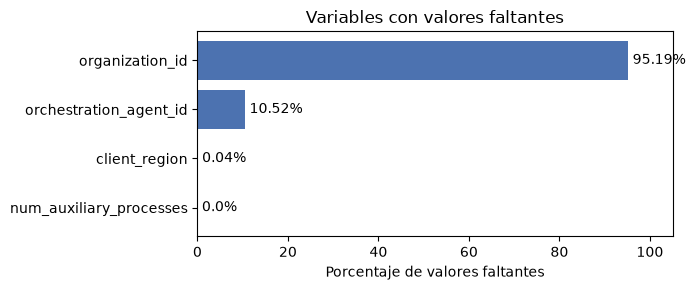

In [6]:
# VALORES FALTANTES

# Nos quedamos solo con las variables que tienen al menos un nulo
faltantes = diccionario.loc[diccionario["nulos"] > 0, ["nulos"]].copy()
faltantes["porcentaje"] = (faltantes["nulos"] / len(df) * 100).round(2)
faltantes = faltantes.sort_values("nulos", ascending=False)

print(faltantes)

# Gráfico de barras horizontales con el porcentaje de nulos
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(faltantes.index, faltantes["porcentaje"], color="#4C72B0")

# Escribimos el porcentaje al lado de cada barra
for i, v in enumerate(faltantes["porcentaje"]):
    ax.text(v + 1, i, f"{v}%", va="center")

ax.invert_yaxis()  # la variable con más nulos queda arriba
ax.set_xlim(0, 105)
ax.set_xlabel("Porcentaje de valores faltantes")
ax.set_title("Variables con valores faltantes")
plt.tight_layout()
plt.show()

Solo 4 variables tienen valores faltantes:

- **`organization_id`** (95,19%): la gran mayoría de las reservas no tiene organización asociada. El nulo probablemente significa **"sin organización"** y no un error de carga, así que en lugar de eliminar filas se tratará como una categoría propia.
- **`orchestration_agent_id`** (10,52%): ocurre lo mismo, el nulo probablemente significa **"sin agente"**.
- **`client_region`** (20 filas) y **`num_auxiliary_processes`** (1 fila): son casos aislados. Se imputarán dentro del pipeline (con la moda o la mediana), ajustando la imputación solo con los datos de entrenamiento.

### 2.3 Variable objetivo

              cantidad  porcentaje
canceled_job                      
0                27887       58.29
1                19955       41.71


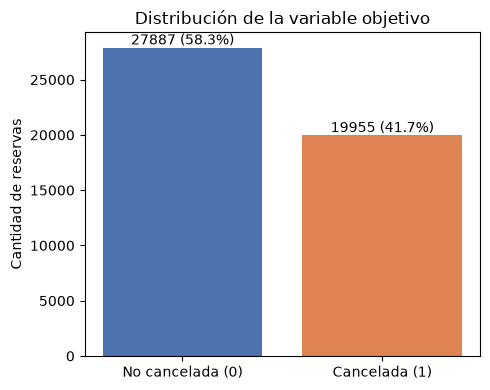

In [7]:
# DISTRIBUCIÓN DE LA VARIABLE OBJETIVO

conteo = df["canceled_job"].value_counts().sort_index()
porcentaje = df["canceled_job"].value_counts(normalize=True).sort_index() * 100

print(pd.DataFrame({"cantidad": conteo, "porcentaje": porcentaje.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No cancelada (0)", "Cancelada (1)"], conteo.values, color=["#4C72B0", "#DD8452"])

# Escribimos el valor arriba de cada barra
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({porcentaje.values[i]:.1f}%)", ha="center", va="bottom")

ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de reservas")
plt.tight_layout()
plt.show()

El **58,3%** de las reservas no se canceló y el **41,7%** sí. Hay un **desbalance moderado**, mucho menor que el del TP2 (donde la clase positiva era el 11%).

Igualmente, este desbalance justifica dos decisiones:

- Usar **`stratify`** al separar train y test, para que ambos conjuntos mantengan la misma proporción de cancelaciones.
- Evaluar con **Balanced Accuracy**, la métrica de la competencia. Promedia el recall de cada clase, así que un modelo que favorezca a la clase mayoritaria no obtiene un buen puntaje.

### 2.4 Categorías poco frecuentes

Las categorías con muy pocas observaciones son un problema para los modelos: no hay suficientes ejemplos para aprender su comportamiento. Identificamos las categorías que representan **menos del 1%** de las reservas.

In [8]:
# CATEGORÍAS POCO FRECUENTES (< 1% DE LAS RESERVAS)

umbral = 1  # porcentaje

cols_categoricas = [
    "service_tier",
    "client_type",
    "request_channel",
    "reserved_gpu_type",
    "assigned_gpu_type",
    "reservation_commitment",
    "workload_profile",
    "client_region",
]

filas = []

for col in cols_categoricas:

    # Porcentaje de reservas en cada categoría
    porc = df[col].value_counts(normalize=True) * 100

    # Categorías que no llegan al umbral
    raras = porc[porc < umbral]

    filas.append({
        "variable": col,
        "n_categorias": df[col].nunique(),
        "categorias_raras": len(raras),
        "reservas_en_categorias_raras": int(df[col].isin(raras.index).sum()),
        "ejemplos": ", ".join(raras.index[:5].astype(str)),
    })

pd.DataFrame(filas).set_index("variable")

,n_categorias,categorias_raras,reservas_en_categorias_raras,ejemplos
variable,,,,
service_tier,4,1,9,enterprise
client_type,8,3,464,"sponsored_project, high_priority_partner, unknown"
request_channel,5,2,110,"scheduler_gateway, unknown"
reserved_gpu_type,8,3,296,"GPU_T7, GPU_T3, GPU_T12"
assigned_gpu_type,9,4,670,"GPU_T7, GPU_T10, GPU_T3, GPU_T12"
reservation_commitment,3,1,12,flexible_commitment
workload_profile,4,1,177,team_project
client_region,149,135,5327,"ISR, SWE, POL, CN, NOR"


Todas las variables categóricas tienen al menos una categoría poco frecuente:

- **`client_region`** es el caso más extremo: **135 de sus 149 países** representan menos del 1% de las reservas cada uno.
- En **`client_type`** y **`request_channel`** aparece la categoría `unknown` con **una sola reserva**.
- En **`service_tier`**, `enterprise` tiene solo **9 reservas**. En **`reservation_commitment`**, `flexible_commitment` tiene solo **12**.

Para evitar que el modelo aprenda patrones a partir de muy pocos casos, estas categorías se agruparán en una categoría **"otros"**. La agrupación se definirá usando solo el conjunto de entrenamiento.

### 2.5 Conclusiones de la exploración inicial

| Hallazgo | Decisión |
|---|---|
| `execution_status` y `execution_status_date` contienen el resultado de la reserva | Eliminarlas (data leakage) |
| `total_gpu_hours` y `total_processes` son sumas de otras variables | Eliminarlas (redundantes) |
| `organization_id` y `orchestration_agent_id` son identificadores con muchos nulos | Tratarlas como categóricas, con el nulo como categoría "sin organización" / "sin agente" |
| `client_region` y `num_auxiliary_processes` tienen pocos nulos | Imputar dentro del pipeline |
| Desbalance moderado (58% / 42%) | Usar `stratify` y Balanced Accuracy |
| Categorías poco frecuentes | Agruparlas en "otros" |

El siguiente paso es **separar train y test**. Recién después se analizará la relación de cada variable con la cancelación.

## 3. Separación en train y test

Antes de analizar la relación de las variables con el target, separamos un conjunto de **test** que no se usará hasta la evaluación final. Antes del split hay dos pasos: eliminar las variables con leakage y decidir qué hacer con las filas duplicadas.

### 3.1 Eliminación de variables con leakage

Como se vio en la sección 1, `execution_status` y `execution_status_date` contienen el resultado de la reserva. Se eliminan antes del split para que no lleguen a ningún modelo.

In [ ]:
# ELIMINACIÓN DE VARIABLES CON LEAKAGE

cols_leakage = ["execution_status", "execution_status_date"]

# Trabajamos sobre una copia para no modificar el df original
df_modelo = df.drop(columns=cols_leakage)

print("Columnas antes:", df.shape[1])
print("Columnas después:", df_modelo.shape[1])

### 3.2 Filas duplicadas

Verificamos si hay reservas con exactamente los mismos valores en todas las variables (sin contar el target).

In [ ]:
# FILAS DUPLICADAS

# Columnas que describen la reserva (todas menos el target)
cols_features = df_modelo.columns.drop("canceled_job")

# keep=False marca todas las copias, no solo las repetidas
duplicadas = df_modelo.duplicated(subset=cols_features, keep=False)
print(f"Filas con al menos una copia idéntica: {duplicadas.sum()} ({duplicadas.mean() * 100:.1f}%)")

# Asignamos un número de grupo a cada combinación distinta de valores.
# Las filas idénticas comparten el mismo número de grupo.
# dropna=False hace que los nulos también se consideren iguales entre sí.
grupos = df_modelo.groupby(list(cols_features), dropna=False).ngroup()

tamanio_grupos = grupos.value_counts()
print("Grupos con más de una fila:", (tamanio_grupos > 1).sum())
print("Tamaño del grupo más grande:", tamanio_grupos.max())

print("\nCantidad de grupos según su tamaño (primeros 10):")
print(tamanio_grupos[tamanio_grupos > 1].value_counts().sort_index().head(10))

El **40,6%** de las filas (19.435) tiene al menos una copia idéntica. Forman **3.499 grupos**: la mayoría son pares, pero hay grupos de hasta **180 filas** iguales.

El dataset **no tiene un identificador de reserva**, así que no se puede saber con certeza si son errores de carga o reservas distintas. Grupos tan grandes (misma fecha, mismo agente, mismo precio) sugieren **reservas en bloque**: un cliente que reserva muchas GPUs a la vez. Por eso **no se eliminan**.

El riesgo de conservarlas es que una copia quede en train y otra en test: el modelo se evaluaría sobre filas que ya vio y la métrica saldría optimista. Para evitarlo, el split se hace **por grupos**.

### 3.3 Split estratificado por grupos

Usamos `StratifiedGroupKFold` con 5 folds y tomamos uno como test (**20%**). Así se cumplen dos condiciones:

- **Estratificado:** train y test mantienen la proporción de cancelaciones.
- **Por grupos:** cada grupo de filas idénticas queda entero en train o en test.

La asignación de los grupos es aleatoria. La semilla (`random_state=42`) se fija una sola vez y no se cambia según los resultados, para no elegir un test "a medida". Los mismos grupos se usarán después en la validación cruzada.

In [ ]:
# SPLIT TRAIN / TEST

from sklearn.model_selection import StratifiedGroupKFold

X = df_modelo.drop(columns="canceled_job")
y = df_modelo["canceled_job"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Tomamos el primer fold como test (1 de 5 = 20%)
idx_train, idx_test = next(sgkf.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

# Guardamos los grupos de train para usarlos en la validación cruzada
grupos_train = grupos.iloc[idx_train]

# Verificación 1: tamaño y proporción de cancelaciones en cada conjunto
print(pd.DataFrame({
    "filas": [len(y_train), len(y_test)],
    "porc_filas": [round(len(y_train) / len(y) * 100, 2), round(len(y_test) / len(y) * 100, 2)],
    "porc_canceladas": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"]))

# Verificación 2: ningún grupo de duplicados aparece en ambos conjuntos
compartidos = set(grupos.iloc[idx_train]) & set(grupos.iloc[idx_test])
print("\nGrupos presentes en train y en test a la vez:", len(compartidos))

El split quedó con **38.274 filas en train (80%)** y **9.568 en test (20%)**, ambos con **41,7% de cancelaciones**, y ningún grupo de duplicados aparece en los dos conjuntos.

A partir de acá, **el test no se vuelve a mirar** hasta la evaluación final. Todo el análisis y las decisiones siguientes se hacen solo con train.

## 4. Análisis exploratorio

Con el test ya separado, se analiza la relación entre cada variable y la cancelación. Todo este análisis usa **únicamente el conjunto de entrenamiento**: mirar el test en esta etapa equivaldría a tomar decisiones a partir de datos que deben quedar reservados para la evaluación final.

### 4.1 Variables numéricas

Para cada variable numérica se compara su valor promedio entre reservas canceladas y no canceladas, y se calcula su correlación con el target.

In [ ]:
# RELACIÓN DE LAS VARIABLES NUMÉRICAS CON EL TARGET

# Juntamos features y target en un solo DataFrame, solo para el análisis
train = X_train.copy()
train["canceled_job"] = y_train

# Numéricas: todas las que no son categóricas de texto
cols_numericas_eda = [c for c in X_train.columns if c not in cols_categoricas]

# Valor promedio de cada variable en cada clase
comparacion = train.groupby("canceled_job")[cols_numericas_eda].mean().T
comparacion.columns = ["no_cancelada", "cancelada"]
comparacion["diferencia"] = comparacion["cancelada"] - comparacion["no_cancelada"]

# Correlación de cada variable con el target
comparacion["correlacion"] = [train[c].corr(train["canceled_job"])
                              for c in cols_numericas_eda]

# Ordenamos por correlación en valor absoluto: arriba las más informativas
orden = comparacion["correlacion"].abs().sort_values(ascending=False).index

comparacion.reindex(orden).round(3)

Las variables numéricas más relacionadas con la cancelación son:

- **`special_resource_requests`** (correlación −0,29): las reservas que no se cancelan piden en promedio 0,74 solicitudes especiales, contra 0,28 las que sí se cancelan. Pedir extras parece indicar un cliente comprometido con la reserva.
- **`hours_before_execution`** (+0,28): las canceladas se reservaron con **143 horas** de anticipación en promedio, frente a **81** las no canceladas. Reservar con mucha antelación da más tiempo y más motivos para cancelar.
- **`previous_job_cancellations`** (+0,17): quien ya canceló antes vuelve a cancelar.
- **`resource_modifications`** (−0,15) y **`reserved_storage_units`** (−0,13): modificar la reserva o reservar almacenamiento también indican compromiso.

En el otro extremo, las variables temporales (`execution_year`, `execution_month`, `execution_week`, `execution_day`) y los identificadores tienen correlaciones prácticamente nulas (|r| < 0,02). Eso no significa que no sirvan: la correlación solo detecta relaciones **lineales**, y un árbol puede aprovecharlas de otra forma. Por eso no se descartan en esta instancia.

### 4.2 Variables categóricas

Para cada categoría se calcula la proporción de reservas canceladas. Se muestran solo las categorías con al menos 30 reservas, porque con menos casos la proporción no es confiable.

In [ ]:
# TASA DE CANCELACIÓN POR CATEGORÍA

# Con menos de 30 reservas la proporción no es confiable
minimo_reservas = 30

for col in cols_categoricas:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )

    # Dejamos afuera las categorías con muy pocos casos
    tabla = tabla[tabla["reservas"] >= minimo_reservas]

    # client_region tiene 149 categorías: mostramos solo las más frecuentes
    if col == "client_region":
        tabla = tabla.sort_values("reservas", ascending=False).head(8)
    else:
        tabla = tabla.sort_values("tasa_cancelacion", ascending=False)

    print(f"\n=== {col} ===")
    print(tabla.round(3))

Hay variables categóricas que separan muy bien las dos clases:

- **`reservation_commitment`**: las reservas con `locked_allocation` se cancelan en el **99,8%** de los casos (6.274 reservas), frente al 30,3% de `no_commitment`. Es la variable más predictiva del dataset. Es información contractual conocida al momento de reservar, así que no constituye leakage, pero una variable que determina el resultado casi por completo merece mencionarse explícitamente.
- **`client_type`**: va del **66,8%** en `research_consortium` al **11,8%** en `sponsored_project`.
- **`request_channel`**: `broker_platform` cancela el **45,1%** y `api_direct` el **18,0%**. Reservar a través de un intermediario se asocia a mucha más cancelación que hacerlo directo por API.
- **`workload_profile`**: `single_experiment` cancela el 46,1% y `multi_run_experiment` el 26,6%.

### 4.3 Análisis por cohortes

La consigna pide analizar el comportamiento por cohortes, en particular según `client_type`, `service_tier` y `reserved_gpu_type`. Además del porcentaje de cancelación interesa el **peso de cada cohorte**: una cohorte con mala performance pero pocas reservas afecta poco al resultado global.

In [ ]:
# ANÁLISIS POR COHORTES

cols_cohortes = ["client_type", "service_tier", "reserved_gpu_type"]

for col in cols_cohortes:

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa_cancelacion=("canceled_job", "mean"),
    )
    # El peso de la cohorte importa tanto como su tasa
    tabla["porc_del_train"] = tabla["reservas"] / len(train) * 100

    print(f"\n=== {col} ===")
    print(tabla.sort_values("reservas", ascending=False).round(3))

# Gráfico: tasa de cancelación de cada cohorte, con su tamaño al lado
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, cols_cohortes):

    tabla = train.groupby(col).agg(
        reservas=("canceled_job", "size"),
        tasa=("canceled_job", "mean"),
    )
    # Solo cohortes con suficientes casos como para que la tasa sea confiable
    tabla = tabla[tabla["reservas"] >= minimo_reservas].sort_values("tasa")

    ax.barh(tabla.index, tabla["tasa"] * 100, color="#4C72B0")

    # Cantidad de reservas al lado de cada barra
    for i, (t, n) in enumerate(zip(tabla["tasa"], tabla["reservas"])):
        ax.text(t * 100 + 1, i, f"n={n}", va="center", fontsize=8)

    # Línea de referencia con la tasa global
    ax.axvline(train["canceled_job"].mean() * 100, color="#DD8452", linestyle="--")

    ax.set_xlim(0, 115)
    ax.set_xlabel("% de cancelación")
    ax.set_title(col)

plt.tight_layout()
plt.show()

La línea naranja marca la tasa global de cancelación del train (41,7%).

- **`client_type`** es la cohorte más útil de las tres. `cloud_marketplace` concentra el **48,4%** de las reservas y cancela por debajo del promedio (37,6%), mientras que `research_consortium` es el **17,3%** del train y cancela el **66,8%**. Son dos poblaciones con comportamientos muy distintos.
- **`service_tier`** casi no discrimina: `standard` (78,5% de las reservas) cancela 42,9% y `priority` 36,9%. La diferencia es chica comparada con las otras cohortes.
- **`reserved_gpu_type`** está muy concentrada: `GPU_T1` es el **78,8%** del train. El resto de los tipos tienen tasas entre 26,7% y 40,3%, pero cada uno representa pocos casos.

Las cohortes `unknown` en `client_type` (1 reserva), `enterprise` en `service_tier` (8) y `GPU_T12` / `GPU_T3` en `reserved_gpu_type` (5 y 8) tienen demasiado pocos casos para sacar conclusiones. Se agruparán en "otros" durante el preprocesamiento.

### 4.4 Outliers y valores atípicos

Siguiendo el criterio del rango intercuartílico (IQR), se consideran atípicos los valores por encima de `Q3 + 1,5 × IQR`.

In [ ]:
# OUTLIERS: CRITERIO DEL RANGO INTERCUARTÍLICO (IQR)

cols_revisar = [
    "hours_before_execution",
    "estimated_cost_per_hour",
    "total_gpu_hours",
    "queue_wait_time",
    "num_background_processes",
]

filas_iqr = []

for col in cols_revisar:

    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1

    # Todo lo que supere este límite se considera atípico
    limite_superior = q3 + 1.5 * iqr

    filas_iqr.append({
        "variable": col,
        "mediana": train[col].median(),
        "maximo": train[col].max(),
        "limite_IQR": limite_superior,
        "n_atipicos": int((train[col] > limite_superior).sum()),
    })

print(pd.DataFrame(filas_iqr).set_index("variable").round(2))

# Boxplots para ver la forma de cada distribución
fig, axes = plt.subplots(1, len(cols_revisar), figsize=(15, 3.5))

for ax, col in zip(axes, cols_revisar):
    ax.boxplot(train[col].dropna(), widths=0.6)
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

# Miramos de cerca los dos casos sospechosos de ser errores de carga
print("\nnum_background_processes:")
print(train["num_background_processes"].value_counts().sort_index())

print("\nestimated_cost_per_hour:")
print("  reservas con costo 0:", (train["estimated_cost_per_hour"] == 0).sum())
print("  reservas con costo mayor a 100:", (train["estimated_cost_per_hour"] > 100).sum())

Conviene distinguir dos situaciones distintas:

**Valores extremos pero plausibles.** `hours_before_execution` llega a 629 horas y `total_gpu_hours` a 456: son reservas grandes o hechas con mucha anticipación, pero perfectamente posibles. `queue_wait_time` tiene mediana 0, así que el criterio IQR marca como atípica cualquier espera mayor a cero, lo cual no tiene sentido tratar como error. En estos casos **no se eliminan filas**: son parte de la variabilidad real del problema.

**Valores sospechosos de ser errores de carga.** Acá sí aparecen dos casos concretos:

- **`num_background_processes`**: 38.101 reservas tienen 0, 169 tienen 1 y 3 tienen 2. Y aparece **una sola reserva con 10**. Un salto de 2 a 10 con un único caso no parece un valor real.
- **`estimated_cost_per_hour`**: la mediana es 4,97 USD y hay **una sola reserva con 270**, más de 50 veces la mediana. Además hay **601 reservas con costo 0**, que podrían ser cortesías o errores de registro.

Son muy pocos casos (menos del 1,6% del train) y los modelos basados en árboles son robustos a valores extremos, así que **no se eliminan**. Quedan identificados por si el análisis de errores más adelante los señala como problemáticos.

### 4.5 Variables con información posterior a la reserva

En la sección 1 se eliminaron `execution_status` y `execution_status_date` por contener el resultado de la reserva. Queda una variable con un problema parecido pero más sutil: **`assigned_gpu_type`**, el tipo de GPU finalmente asignado.

In [ ]:
# ¿assigned_gpu_type APORTA INFORMACIÓN POSTERIOR A LA RESERVA?

# Marcamos si la GPU asignada es distinta de la que se había reservado
gpu_cambiada = train["assigned_gpu_type"] != train["reserved_gpu_type"]

tabla_gpu = train.groupby(gpu_cambiada).agg(
    reservas=("canceled_job", "size"),
    tasa_cancelacion=("canceled_job", "mean"),
)
tabla_gpu.index = ["Misma GPU que la reservada", "Le cambiaron la GPU"]

print(tabla_gpu.round(3))

El resultado es contundente: cuando la GPU asignada difiere de la reservada (3.497 reservas, el 9,1% del train), la tasa de cancelación baja al **6,4%**, frente al **45,3%** cuando no hubo cambio.

La explicación es que **una reserva solo se reasigna a otra GPU si efectivamente va a ejecutarse**. Es decir, que la GPU haya cambiado es consecuencia de que la reserva no se canceló, no una causa de ello. Es el mismo mecanismo que `execution_status`, pero en versión probabilística en lugar de determinista.

Se decide **conservarla**, por dos motivos:

1. La cátedra la incluye en el conjunto de evaluación: el enunciado del leaderboard aclara que la entrada viene sin `canceled_job`, `execution_status` ni `execution_status_date`, pero no excluye `assigned_gpu_type`.
2. Su impacto se medirá explícitamente en la etapa de optimización, entrenando con y sin ella.

### 4.6 Conclusiones del análisis exploratorio

| Hallazgo | Implicancia |
|---|---|
| `reservation_commitment = locked_allocation` cancela el 99,8% | Variable muy predictiva, pero conocida al reservar: se conserva |
| `hours_before_execution` y `special_resource_requests` son las numéricas más informativas | Candidatas a transformaciones o combinaciones |
| `client_type` separa fuerte (66,8% vs 11,8%); `service_tier` casi no separa | `client_type` es la cohorte útil para el análisis de errores |
| Variables temporales con correlación casi nula | Se conservan: los árboles pueden aprovecharlas de forma no lineal |
| Pocos outliers y en su mayoría plausibles | No se eliminan filas |
| `assigned_gpu_type` contiene información posterior a la reserva | Se conserva y se mide su impacto por separado |

## 5. Preprocesamiento

Las transformaciones se arman dentro de un **`Pipeline` de scikit-learn** en lugar de aplicarlas directamente sobre el DataFrame. Esto tiene tres ventajas:

- Los parámetros de cada transformación (la mediana para imputar, la media y el desvío para escalar, las categorías conocidas) se calculan **solo con train** y se aplican tal cual a validación y test. Así se evita el data leakage.
- El mismo objeto se puede aplicar a datos nuevos sin repetir código, que es exactamente lo que necesita la función predictora de la etapa final.
- Las transformaciones quedan dentro de la validación cruzada, así que cada fold se preprocesa con sus propios datos de entrenamiento.

### 5.1 Grupos de columnas

Las columnas se separan en tres grupos, porque cada uno necesita un tratamiento distinto, más un cuarto grupo que se descarta.

In [ ]:
# GRUPOS DE COLUMNAS SEGÚN SU TRATAMIENTO

# Redundantes: son sumas exactas de otras columnas (verificado en la sección 1)
cols_redundantes = ["total_processes", "total_gpu_hours"]

# Identificadores: pandas los lee como números, pero son etiquetas.
# Además concentran casi todos los valores faltantes del dataset.
cols_identificadores = ["orchestration_agent_id", "organization_id"]

# Nominales: las categóricas de texto, definidas en la sección 2.4
cols_nominales = list(cols_categoricas)

# Numéricas: todo lo que no entra en los grupos anteriores
cols_numericas = [c for c in X_train.columns
                  if c not in cols_redundantes + cols_identificadores + cols_nominales]

resumen_grupos = pd.DataFrame({
    "grupo": ["Numéricas", "Nominales", "Identificadores", "Redundantes (se descartan)"],
    "columnas": [len(cols_numericas), len(cols_nominales),
                 len(cols_identificadores), len(cols_redundantes)],
})

print(resumen_grupos.to_string(index=False))

print("\nNuméricas:", cols_numericas)
print("\nNominales:", cols_nominales)

### 5.2 Construcción del pipeline

Cada grupo recibe su propio tratamiento:

| Grupo | Valores faltantes | Transformación |
|---|---|---|
| Numéricas | Mediana (robusta a los valores extremos de la sección 4.4) | `StandardScaler` |
| Nominales | Categoría más frecuente | `OneHotEncoder` |
| Identificadores | Constante `-1`, que representa "sin agente" / "sin organización" | `OneHotEncoder` |

Dos decisiones del `OneHotEncoder` merecen explicación:

- **`min_frequency=0.01`** agrupa automáticamente en una sola columna todas las categorías que representan menos del 1% de los datos. Es la agrupación en "otros" que se anticipó en la sección 2.4, y resuelve el problema de los 149 países de `client_region` y de los 194 agentes de orquestación.
- **`handle_unknown="infrequent_if_exist"`** hace que una categoría nunca vista en entrenamiento se trate como una categoría poco frecuente más, en lugar de producir un error. Sin esto, la función predictora fallaría si en el conjunto de evaluación apareciera un país que no está en train.

El escalado no es necesario para los modelos basados en árboles, pero sí para la regresión logística y los métodos basados en distancias. Se incluye para poder comparar todas las familias de clasificadores con el mismo pipeline.

In [ ]:
# PIPELINE DE PREPROCESAMIENTO

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pipe_numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

pipe_nominales = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

pipe_identificadores = Pipeline([
    # El -1 representa "sin agente" / "sin organización"
    ("imputar", SimpleImputer(strategy="constant", fill_value=-1)),
    ("codificar", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=0.01,
                                sparse_output=False)),
])

# remainder="drop" deja afuera las columnas redundantes
preprocesador = ColumnTransformer([
    ("numericas", pipe_numericas, cols_numericas),
    ("nominales", pipe_nominales, cols_nominales),
    ("identificadores", pipe_identificadores, cols_identificadores),
], remainder="drop")

# Lo ajustamos SOLO con train
X_train_pre = preprocesador.fit_transform(X_train)

print("X_train:", X_train.shape, "->", X_train_pre.shape)
print("Valores faltantes después de preprocesar:", int(np.isnan(X_train_pre).sum()))

# Cuántas columnas generó cada variable de alta cardinalidad
nombres_columnas = preprocesador.get_feature_names_out()

print("\nColumnas generadas por las variables de alta cardinalidad:")
for col in ["client_region", "orchestration_agent_id", "organization_id"]:
    print(f"  {col}: {sum(col in n for n in nombres_columnas)} columnas")

El pipeline transforma las **31 columnas** originales en **84 columnas** numéricas, sin valores faltantes. La agrupación de categorías poco frecuentes reduce `client_region` de 149 países a 15 columnas y los 194 agentes de orquestación a 14, evitando que la dimensionalidad explote.

Dos aclaraciones sobre cómo se usa de acá en adelante:

- El `preprocesador` se ajustó con train **solo para verificar que funciona**. En la validación cruzada no se usará este objeto ya ajustado: se lo encadenará con cada clasificador dentro de un `Pipeline` completo, de modo que en cada fold se reajuste únicamente con los datos de entrenamiento de ese fold.
- `X_test` todavía no se tocó. Se transformará recién en la evaluación final.

Con esto queda cerrada la etapa de preprocesamiento y análisis exploratorio. El siguiente paso es entrenar los primeros clasificadores y establecer un baseline.